<a href="https://colab.research.google.com/github/fathimanoorjahan03-afk/ROADSHIELD/blob/main/Road_Shield_Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 2. Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 3. Load Raw Dataset

raw_df = pd.read_csv(
    '/content/drive/MyDrive/Main project/raw_data/road_collision_2023_2025.csv'
)

# Create a working copy
df = raw_df.copy()

print("Original Dataset Shape:", raw_df.shape)
print("Working Dataset Shape:", df.shape)

display(df.head())

Original Dataset Shape: (306710, 44)
Working Dataset Shape: (306710, 44)


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,2023170M20483,2023,170M20483,451177.0,519211.0,-1.210024,54.565548,17,3,1,...,0,0,1,2,2,E01012077,-1,0,0.03426,0.96574
1,2023170M10633,2023,170M10633,450248.0,518901.0,-1.224443,54.562855,17,2,2,...,0,0,1,1,2,E01012026,-1,0,1.00000,0.00000
2,2023170S11103,2023,170S11103,443464.0,518662.0,-1.329383,54.561334,17,3,1,...,0,0,1,2,2,E01012217,-1,0,0.05072,0.94928
3,2023111343936,2023,111343936,426760.0,517238.0,-1.587814,54.549692,11,2,1,...,0,0,2,1,2,E01033481,6,1,1.00000,0.00000
4,2023070054936,2023,070054936,361439.0,393070.0,-2.581866,53.432995,7,3,2,...,0,0,2,2,2,E01012468,-1,0,0.00366,0.99634


In [ ]:
# 4. Dataset Inspection

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
display(df['collision_severity'].value_counts(dropna=False))

Dataset Shape: (306710, 44)

Column Names:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_seve

,0
location_easting_osgr,14
location_northing_osgr,14
longitude,14
latitude,14



Duplicate Rows:
0

Target Distribution:


,count
collision_severity,
3,230037
2,72196
1,4477


In [ ]:
# 5. Duplicate Identifier Analysis

identifier_cols = [
    'collision_index',
    'collision_ref_no'
]

for col in identifier_cols:

    print(f"\nColumn: {col}")

    print("Unique values:", df[col].nunique())

    print("Duplicate values:", df[col].duplicated().sum())

    print("Missing values:", df[col].isnull().sum())


Column: collision_index
Unique values: 306710
Duplicate values: 0
Missing values: 0

Column: collision_ref_no
Unique values: 304106
Duplicate values: 2604
Missing values: 0


In [ ]:
# 6. Duplicate Records and Year Coverage

# Check completely duplicated rows
print("Duplicate complete rows:", df.duplicated().sum())

# Check collision records by year
print("\nCollision records by year:")
display(
    df['collision_year']
    .value_counts(dropna=False)
    .sort_index()
)

# Check date range
df['date'] = pd.to_datetime(
    df['date'],
    dayfirst=True,
    errors='coerce'
)

print("\nDate range:")
print("Start date:", df['date'].min())
print("End date:", df['date'].max())

# Check total records
print("\nTotal collision records:", len(df))

Duplicate complete rows: 0

Collision records by year:


,count
collision_year,
2023,104258
2024,100927
2025,101525



Date range:
Start date: 2023-01-01 00:00:00
End date: 2025-12-31 00:00:00

Total collision records: 306710


In [ ]:
# 7. Missing Value Analysis

missing_values = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[
    missing_values['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_values)

# We should not impute geographical coordinates because artificial coordinates could create incorrect hotspot locations.

,Missing_Count,Missing_Percentage
location_easting_osgr,14,0.004565
location_northing_osgr,14,0.004565
longitude,14,0.004565
latitude,14,0.004565


In [ ]:
# 8. Target Variable Analysis

target_col = 'collision_severity'

# Check missing values
print("Missing target values:",
      df[target_col].isnull().sum())

# Check target distribution
print("\nTarget value counts:")
display(df[target_col].value_counts(dropna=False).sort_index())

# Check target percentages
print("\nTarget percentage distribution:")
display(
    (df[target_col].value_counts(normalize=True, dropna=False)
     .sort_index() * 100).round(2)
)

Missing target values: 0

Target value counts:


,count
collision_severity,
1,4477
2,72196
3,230037



Target percentage distribution:


,proportion
collision_severity,
1,1.46
2,23.54
3,75.00


In [ ]:
# 9. Geographical Missing Value Analysis

geo_cols = [
    'location_easting_osgr',
    'location_northing_osgr',
    'longitude',
    'latitude'
]

print("Missing geographical values:")
display(df[geo_cols].isnull().sum())

# Rows missing all four geographical values
missing_all_geo = df[geo_cols].isnull().all(axis=1).sum()

# Rows missing at least one geographical value
missing_any_geo = df[geo_cols].isnull().any(axis=1).sum()

print("\nRows missing all geographical values:", missing_all_geo)
print("Rows missing at least one geographical value:", missing_any_geo)

Missing geographical values:


,0
location_easting_osgr,14
location_northing_osgr,14
longitude,14
latitude,14



Rows missing all geographical values: 14
Rows missing at least one geographical value: 14


In [ ]:
# 10. Handle Missing Geographical Values

# Create a copy of the original cleaned dataset
df_clean = df.copy()

# Geographical columns
geo_cols = [
    'location_easting_osgr',
    'location_northing_osgr',
    'longitude',
    'latitude'
]

# Create a separate dataset for hotspot analysis
hotspot_df = df_clean.dropna(subset=geo_cols).copy()

# Display results
print("Original dataset shape:", df_clean.shape)
print("Hotspot dataset shape:", hotspot_df.shape)

print("Records excluded from hotspot analysis:",
      len(df_clean) - len(hotspot_df))

print("Missing geographical values in hotspot dataset:",
      hotspot_df[geo_cols].isnull().sum().sum())

Original dataset shape: (306710, 44)
Hotspot dataset shape: (306696, 44)
Records excluded from hotspot analysis: 14
Missing geographical values in hotspot dataset: 0


In [ ]:
# 11. Outlier Detection using IQR
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()


outlier_results = []

for col in numerical_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ).sum()

    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower_Limit': lower_limit,
        'Upper_Limit': upper_limit,
        'Outlier_Count': outlier_count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower_Limit,Upper_Limit,Outlier_Count
0,collision_year,2023.000000,2025.000000,2.000000,2020.000000,2028.000000,0
1,location_easting_osgr,392459.750000,529229.000000,136769.250000,187305.875000,734382.875000,1639
2,location_northing_osgr,175223.750000,382951.500000,207727.750000,-136367.875000,694543.125000,3489
3,longitude,-2.113301,-0.136970,1.976331,-5.077798,2.827527,1522
4,latitude,51.463170,53.339990,1.876820,48.647940,56.155221,3352
5,police_force,5.000000,45.000000,40.000000,-55.000000,105.000000,0
6,collision_severity,3.000000,3.000000,0.000000,3.000000,3.000000,76673
7,number_of_vehicles,1.000000,2.000000,1.000000,-0.500000,3.500000,5948
8,number_of_casualties,1.000000,1.000000,0.000000,1.000000,1.000000,56162
9,day_of_week,2.000000,6.000000,4.000000,-4.000000,12.000000,0


In [ ]:
# 11. Outlier Handling

# No automatic IQR removal or capping
# Retain valid extreme collision records

print("Outlier handling completed.")
print("Total records retained:", len(df_clean))

print("\nNumber of vehicles:")
print("Minimum:", df_clean['number_of_vehicles'].min())
print("Maximum:", df_clean['number_of_vehicles'].max())

print("\nSpeed limits:")
print(sorted(df_clean['speed_limit'].dropna().unique()))

# Retains all collision records.
# Does not remove outliers using IQR.
# Does not apply upper or lower value capping.
# Displays the range of vehicle counts and available speed limits for verification.

Outlier handling completed.
Total records retained: 306710

Number of vehicles:
Minimum: 1
Maximum: 26

Speed limits:
[np.int64(-1), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]


In [ ]:
# 12. Feature Engineering

# Convert date column into datetime format
df_clean['date'] = pd.to_datetime(
    df_clean['date'],
    dayfirst=T\rue,
    errors='coerce'
)

# Extract month
df_clean['month'] = df_clean['date'].dt.month

# Extract hour from time
df_clean['hour'] = pd.to_numeric(
    df_clean['time'].astype(str).str.extract(r'^(\d{1,2})')[0],
    errors='coerce'
)


# Display new features
display(
    df_clean[
        ['date', 'time', 'day_of_week',
         'month', 'hour']
    ].head(10)
)

# Check missing values in new features
print("\nMissing values:")
display(
    df_clean[['month', 'hour']].isnull().sum()
)

,date,time,day_of_week,month,hour
0,2023-03-04,12:10,7,3,12
1,2023-04-16,20:54,1,4,20
2,2023-06-27,09:30,3,6,9
3,2023-08-14,09:03,2,8,9
4,2023-01-19,08:45,5,1,8
5,2023-04-23,13:00,1,4,13
6,2023-08-02,16:30,4,8,16
7,2023-11-26,15:23,1,11,15
8,2023-01-07,10:15,7,1,10
9,2023-09-15,17:28,6,9,17



Missing values:


,0
month,0
hour,0


In [ ]:
# 13. Prepare Features and Target

target_col = 'collision_severity'

# Columns not suitable as prediction features
drop_cols = [
    'collision_index',
    'collision_ref_no',
    'date',
    'time',
    'local_authority_district',
    'number_of_casualties',
    'did_police_officer_attend_scene_of_accident',
    'enhanced_severity_collision',
    'collision_injury_based',
    'collision_adjusted_severity_serious',
    'collision_adjusted_severity_slight'
]

# Create feature dataset and target
X = df_clean.drop(columns=drop_cols + [target_col], errors='ignore')
y = df_clean[target_col]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().sort_index())

Feature dataset shape: (306710, 34)
Target dataset shape: (306710,)

Target distribution:


,count
collision_severity,
1,4477
2,72196
3,230037


In [ ]:
# 14. Identify Numerical and Categorical Features

# Categorical columns stored as numerical codes
categorical_code_cols = [
    'police_force',
    'day_of_week',
    'first_road_class',
    'road_type',
    'junction_detail_historic',
    'junction_detail',
    'junction_control',
    'second_road_class',
    'pedestrian_crossing_human_control_historic',
    'pedestrian_crossing_physical_facilities_historic',
    'pedestrian_crossing',
    'light_conditions',
    'weather_conditions',
    'road_surface_conditions',
    'special_conditions_at_site',
    'carriageway_hazards_historic',
    'carriageway_hazards',
    'urban_or_rural_area',
    'trunk_road_flag'
]

# Include all object-type columns
categorical_cols = list(
    X.select_dtypes(include=['object', 'category']).columns
)

# Add numerical-coded categorical columns that exist in X
categorical_cols += [
    col for col in categorical_code_cols
    if col in X.columns and col not in categorical_cols
]

# Numerical features are the remaining numeric columns
numerical_cols = [
    col for col in X.select_dtypes(include=np.number).columns
    if col not in categorical_cols
]

print("Categorical features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical features:", len(numerical_cols))
print(numerical_cols)

Categorical features: 23
['local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'lsoa_of_accident_location', 'police_force', 'day_of_week', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag']

Numerical features: 11
['collision_year', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'number_of_vehicles', 'first_road_number', 'speed_limit', 'second_road_number', 'month', 'hour']


In [ ]:
# 14. Final Feature Selection

# Columns excluded from severity prediction
exclude_features = [
    'lsoa_of_accident_location',
    'first_road_number',
    'second_road_number',
    'location_easting_osgr',
    'location_northing_osgr',
    'local_authority_highway'
]

# Remove selected features
X = X.drop(columns=exclude_features, errors='ignore')

# Update categorical features
categorical_cols = [
    col for col in categorical_cols
    if col in X.columns and col != 'lsoa_of_accident_location'
]

# Update numerical features
numerical_cols = [
    col for col in X.select_dtypes(include=np.number).columns
    if col not in categorical_cols
]

print("Updated feature dataset shape:", X.shape)

print("\nCategorical features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical features:", len(numerical_cols))
print(numerical_cols)

Updated feature dataset shape: (306710, 28)

Categorical features: 21
['local_authority_ons_district', 'local_authority_highway_current', 'police_force', 'day_of_week', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag']

Numerical features: 7
['collision_year', 'longitude', 'latitude', 'number_of_vehicles', 'speed_limit', 'month', 'hour']


In [ ]:
# 15. Temporal Train-Test Split

# Separate records based on collision year
train_mask = df_clean['collision_year'].isin([2023, 2024])
test_mask = df_clean['collision_year'] == 2025

# Remove collision_year from model features
X_model = X.drop(columns=['collision_year'])

# Create training and testing datasets
X_train = X_model.loc[train_mask].copy()
X_test = X_model.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Display dataset shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining year distribution:")
display(df_clean.loc[train_mask, 'collision_year'].value_counts())

print("\nTesting year distribution:")
display(df_clean.loc[test_mask, 'collision_year'].value_counts())

Training features: (205185, 27)
Testing features: (101525, 27)

Training target: (205185,)
Testing target: (101525,)

Training year distribution:


,count
collision_year,
2023,104258
2024,100927



Testing year distribution:


,count
collision_year,
2025,101525


In [ ]:
# Step 16 – Check special codes in training and testing data

special_codes = [-1, 9, 99]

for col in X_train.columns:

    train_counts = X_train[col].value_counts()
    test_counts = X_test[col].value_counts()

    found_train = train_counts[train_counts.index.isin(special_codes)]
    found_test = test_counts[test_counts.index.isin(special_codes)]

    if not found_train.empty or not found_test.empty:

        print(f"\nColumn: {col}")

        print("Training data:")
        print(found_train)

        print("Testing data:")
        print(found_test)


Column: police_force
Training data:
police_force
99    8399
Name: count, dtype: int64
Testing data:
police_force
99    4104
Name: count, dtype: int64

Column: number_of_vehicles
Training data:
number_of_vehicles
9    11
Name: count, dtype: int64
Testing data:
number_of_vehicles
9    7
Name: count, dtype: int64

Column: first_road_class
Training data:
Series([], Name: count, dtype: int64)
Testing data:
first_road_class
-1    6
Name: count, dtype: int64

Column: road_type
Training data:
road_type
9    5745
Name: count, dtype: int64
Testing data:
road_type
9    1953
Name: count, dtype: int64

Column: speed_limit
Training data:
speed_limit
-1    3
Name: count, dtype: int64
Testing data:
Series([], Name: count, dtype: int64)

Column: junction_detail_historic
Training data:
junction_detail_historic
-1     59603
 9      8047
 99     4347
Name: count, dtype: int64
Testing data:
junction_detail_historic
-1     87871
 9       363
 99      275
Name: count, dtype: int64

Column: junction_detail
T

In [ ]:
# Step 16 – Handle missing and special codes

# Work on copies of the split datasets
X_train = X_train.copy()
X_test = X_test.copy()

# Categorical columns where -1 means missing/out of range
missing_categorical_cols = [
    'first_road_class',
    'junction_detail_historic',
    'junction_detail',
    'junction_control',
    'second_road_class',
    'pedestrian_crossing_human_control_historic',
    'pedestrian_crossing_physical_facilities_historic',
    'pedestrian_crossing',
    'light_conditions',
    'weather_conditions',
    'road_surface_conditions',
    'special_conditions_at_site',
    'carriageway_hazards_historic',
    'carriageway_hazards',
    'urban_or_rural_area',
    'trunk_road_flag'
]

# Replace -1 with a Missing category
for col in missing_categorical_cols:
    X_train[col] = X_train[col].replace(-1, 'Missing')
    X_test[col] = X_test[col].replace(-1, 'Missing')

# Handle numerical speed_limit
X_train['speed_limit'] = X_train['speed_limit'].replace(-1, np.nan)
X_test['speed_limit'] = X_test['speed_limit'].replace(-1, np.nan)

# Calculate median using training data only
speed_median = X_train['speed_limit'].median()

X_train['speed_limit'] = X_train['speed_limit'].fillna(speed_median)
X_test['speed_limit'] = X_test['speed_limit'].fillna(speed_median)

print("Special value handling completed.")

print("\nRemaining missing values in training data:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nRemaining missing values in testing data:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

Special value handling completed.

Remaining missing values in training data:
longitude    12
latitude     12
dtype: int64

Remaining missing values in testing data:
longitude    2
latitude     2
dtype: int64


In [ ]:
# Verify special code handling

for col in missing_categorical_cols:

    print(f"\nColumn: {col}")

    print("Training data:")
    print(X_train[col].value_counts().head(15))

    print("Testing data:")
    print(X_test[col].value_counts().head(15))


print("\nSpeed limit after handling:")
print("Training:", sorted(X_train['speed_limit'].unique()))
print("Testing:", sorted(X_test['speed_limit'].unique()))

print("\nSpeed limit median used:", speed_median)


Column: first_road_class
Training data:
first_road_class
3    90014
6    73781
4    25794
5     8980
1     6150
2      466
Name: count, dtype: int64
Testing data:
first_road_class
3          43827
6          36901
4          12975
5           4564
1           3054
2            198
Missing        6
Name: count, dtype: int64

Column: junction_detail_historic
Training data:
junction_detail_historic
Missing    59603
0          55839
3          42722
6          13845
1          10666
9           8047
99          4347
8           3575
7           2501
2           2309
5           1731
Name: count, dtype: int64
Testing data:
junction_detail_historic
Missing    87871
0           5411
3           4079
6           1246
1           1147
8            478
9            363
99           275
7            246
2            219
5            190
Name: count, dtype: int64

Column: junction_detail
Training data:
junction_detail
0          99373
13         57043
16         19002
19         12540
Missing    

In [ ]:
# Number of features created from each preprocessing group

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print("\nFeatures by group:")

for group in ['numerical', 'categorical', 'binary']:
    count = sum(name.startswith(group + '__') for name in feature_names)
    print(f"{group}: {count}")

Total processed features: 144

Features by group:
numerical: 4
categorical: 0
binary: 1


In [ ]:

# Step 17 – Hybrid Encoding and Scaling

# 1. Remove geographical coordinates
X_train = X_train.drop(columns=['longitude', 'latitude'], errors='ignore')
X_test = X_test.drop(columns=['longitude', 'latitude'], errors='ignore')

# 2. Define numerical features
numeric_features = [
    'number_of_vehicles',
    'speed_limit',
    'month',
    'hour'
]

# 3. Define categorical features
categorical_features = [
    col for col in categorical_cols
    if col in X_train.columns
]

# 4. Convert categorical values to strings
for col in categorical_features:
    X_train[col] = X_train[col].fillna('Missing').astype(str)
    X_test[col] = X_test[col].fillna('Missing').astype(str)

# 5. Identify high and low cardinality columns
cardinality = X_train[categorical_features].nunique()

high_cardinality_features = cardinality[
    cardinality > 20
].index.tolist()

low_cardinality_features = cardinality[
    cardinality <= 20
].index.tolist()

print("High-cardinality features:", high_cardinality_features)
print("Low-cardinality features:", low_cardinality_features)

# 6. Frequency Encoding – high-cardinality features only
frequency_maps = {}

for col in high_cardinality_features:
    frequency = X_train[col].value_counts(normalize=True)
    frequency_maps[col] = frequency

    X_train[col] = X_train[col].map(frequency).fillna(0)
    X_test[col] = X_test[col].map(frequency).fillna(0)

# 7. Define binary features
binary_features = ['is_weekend']

# 8. Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', StandardScaler(), numeric_features),

        ('low_cardinality', OneHotEncoder(
            handle_unknown='ignore'
        ), low_cardinality_features),

        ('high_cardinality', 'passthrough', high_cardinality_features),

        ('binary', 'passthrough', binary_features)
    ],
    remainder='drop'
)

# 9. Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# 10. Transform testing data
X_test_processed = preprocessor.transform(X_test)

# 11. Display results
print("\nHybrid encoding and scaling completed!")

print("\nOriginal training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nRemaining missing values:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())


High-cardinality features: ['local_authority_ons_district', 'local_authority_highway_current', 'police_force']
Low-cardinality features: ['day_of_week', 'first_road_class', 'road_type', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'trunk_road_flag']


ValueError: A given column is not a column of the dataframe

Training class counts:
collision_severity
1      3024
2     47005
3    155156
Name: count, dtype: int64

Training class percentages:
collision_severity
1     1.47
2    22.91
3    75.62
Name: proportion, dtype: float64

Testing class counts:
collision_severity
1     1453
2    25191
3    74881
Name: count, dtype: int64


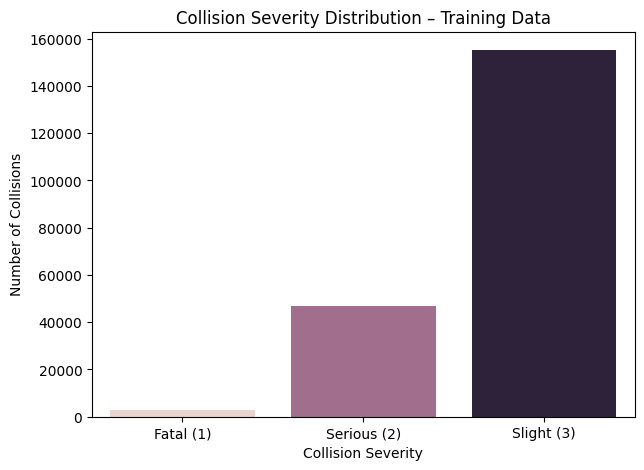

In [ ]:
# Step 18 – Class Imbalance Analysis
# Training target distribution
class_counts = y_train.value_counts().sort_index()

class_percentages = (
    y_train.value_counts(normalize=True).sort_index() * 100
)

print("Training class counts:")
print(class_counts)

print("\nTraining class percentages:")
print(class_percentages.round(2))

print("\nTesting class counts:")
print(y_test.value_counts().sort_index())

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train, hue=y_train, legend=False)

plt.title("Collision Severity Distribution – Training Data")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")
plt.xticks([0, 1, 2], ['Fatal (1)', 'Serious (2)', 'Slight (3)'])

plt.show()

In [ ]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(1): np.float64(22.61739417989418), np.int64(2): np.float64(1.455057972556111), np.int64(3): np.float64(0.4408144061460723)}


In [ ]:
# Check calculated class weights

for class_label, weight in class_weights.items():
    print(f"Class {class_label}: Weight = {weight:.4f}")

Class 1: Weight = 22.6174
Class 2: Weight = 1.4551
Class 3: Weight = 0.4408


In [ ]:
print("========== PREPROCESSING VALIDATION ==========")

print("Training records:", X_train_processed.shape[0])
print("Testing records:", X_test_processed.shape[0])

print("Training features:", X_train_processed.shape[1])
print("Testing features:", X_test_processed.shape[1])



print("Training target missing:", y_train.isnull().sum())
print("Testing target missing:", y_test.isnull().sum())

print("==============================================")

========== PREPROCESSING VALIDATION ==========
Training records: 205185
Testing records: 101525
Training features: 144
Testing features: 144
Training target missing: 0
Testing target missing: 0


In [ ]:
import os
import joblib

save_path = '/content/drive/MyDrive/Main project/notebooks/processed_data'

os.makedirs(save_path, exist_ok=True)

joblib.dump(X_train_processed, save_path + '/X_train.pkl')
joblib.dump(X_test_processed, save_path + '/X_test.pkl')

joblib.dump(y_train, save_path + '/y_train.pkl')
joblib.dump(y_test, save_path + '/y_test.pkl')

print("Preprocessed datasets saved successfully!")

Preprocessed datasets saved successfully!


In [ ]:
joblib.dump(preprocessor, save_path + '/preprocessor.pkl')

['/content/drive/MyDrive/Main project/notebooks/processed_data/preprocessor.pkl']